# Diagnóstico de marca empleadora — Bank Of America vs. peers
## Sentiment analysis (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de Deutsche Bank como empleador, a partir de lo que dicen sus empleados en Glassdoor, y compararlos con los de sus competidores directos.

**Peers elegidos:** Wells-Fargo", "Citi", "HSBC", "J.P.-Morgan". Son bancos globales con negocio de banca de inversión y corporativa, presencia fuerte en Reino Unido y un perfil de empleado parecido al de Deutsche Bank (front office, operaciones, tecnología). Todos superan con holgura las 1000 reseñas.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA: rating, recomendación, empleados actuales vs. antiguos |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic |
| 4 | Comparación con peers: peso de cada topic y balance neto |
| 5 | Empleados actuales vs. antiguos |
| 6 | Conclusiones y recomendaciones para RRHH |




In [10]:
# En Colab: transformers ya viene instalado; BERTopic no.
#!pip install -q bertopic sentence-transformers
#%pip install pyarrow
#%pip install transformers torch

%pip install bertopic sentence-transformers


  Using cached bertopic-0.17.4-py3-none-any.whl.metadata (24 kB)
  Using cached sentence_transformers-6.1.0-py3-none-any.whl.metadata (20 kB)
  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached pynndescent-0.6.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
Using cached bertopic-0.17.4-py3-none-any.whl (154 kB)
Using cached sentence_transformers-6.1.0-py3-none-any.whl (740 kB)
   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ---------------------------------------- 1.9/1.9 MB 48.1 MB/s eta 0:00:00
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)
   ---------------------------------------- 0.0/41.9 MB ? eta -


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import sys
import pandas as pd
import pyarrow

print("Python utilizado:", sys.executable)
print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)


Python utilizado: c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
Pandas: 3.0.1
PyArrow: 26.0.0


---
## 0. Carga y preparación

In [ ]:


import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")



TARGET = "Bank-of-America"


FIRMS_ORIGINALES = [
    "Bank-of-America",
    "Wells-Fargo",
    "Citi",
    "HSBC",
    "J.P.-Morgan",
    "J-P-Morgan"
]


MAX_POR_EMPRESA = 1000
SEED = 42

# Ventana temporal del enunciado: julio de 2018 a julio de 2023.
FECHA_INICIO = "2018-07-01"
FECHA_FIN = "2023-07-31"



RUTA_PARQUET = "glassdoor_reviews_hr.parquet"

raw = pd.read_parquet(
    RUTA_PARQUET,
    filters=[("firm", "in", FIRMS_ORIGINALES)]
)

print("Reseñas cargadas por nombre original:")
print(raw["firm"].value_counts(dropna=False))

# Comprobar qué nombres se han encontrado realmente.
encontradas = set(raw["firm"].dropna().unique())
no_encontradas = set(FIRMS_ORIGINALES) - encontradas

if no_encontradas:
    print("\nAVISO: nombres no encontrados en el dataset:")
    print(sorted(no_encontradas))


MAPA_EMPRESAS = {
    "Bank-of-America": "Bank-of-America",
    "Wells-Fargo": "Wells-Fargo",
    "Citi": "Citi",
    "HSBC": "HSBC",
    "J.P.-Morgan": "J.P.-Morgan",
    "J-P-Morgan": "J.P.-Morgan"
}

raw["firm_original"] = raw["firm"]
raw["firm"] = raw["firm"].map(MAPA_EMPRESAS)

print("\nReseñas por empresa tras normalizar nombres:")
print(raw["firm"].value_counts(dropna=False))



raw["date_review"] = pd.to_datetime(
    raw["date_review"], errors="coerce"
)

df = raw.loc[
    raw["date_review"].between(
        FECHA_INICIO, FECHA_FIN, inclusive="both"
    )
].copy()

print("\nReseñas por empresa dentro de la ventana temporal:")
print(df["firm"].value_counts())

# Revisar que la empresa objetivo esté disponible.
if TARGET not in df["firm"].unique():
    raise ValueError(
        f"No hay reseñas de {TARGET} en la ventana temporal. "
        "Comprueba los nombres y las fechas del dataset."
    )


df = pd.concat(
    [
        grupo.sample(
            n=min(MAX_POR_EMPRESA, len(grupo)),
            random_state=SEED
        )
        for _, grupo in df.groupby("firm")
    ],
    ignore_index=True
)

print(f"\nTotal de reseñas de trabajo: {len(df):,}")
print("\nMuestra final por empresa:")
print(df["firm"].value_counts())



def situacion(valor):
    valor = str(valor).strip().lower()

    if valor.startswith("current"):
        return "Actual"
    elif valor.startswith("former"):
        return "Antiguo"
    else:
        return "Desconocido"


def antiguedad(valor):
    valor = str(valor).strip().lower()

    # Captura expresiones como:
    # "less than 1 year", "more than 3 years"
    patron = r"(less|more) than (\d+)\s+years?"
    coincidencia = re.search(patron, valor)

    if coincidencia:
        return (
            f"{coincidencia.group(1)} than "
            f"{coincidencia.group(2)}y"
        )

    return "n/d"


df["situacion"] = df["current"].map(situacion)
df["antiguedad"] = df["current"].map(antiguedad)

df["recomienda"] = df["recommend"].map({
    "v": "Sí",
    "o": "Neutral",
    "x": "No"
})

df["anio"] = df["date_review"].dt.year


for columna in ["pros", "cons"]:
    df[columna] = (
        df[columna]
        .fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


print("\nTextos vacíos:")
print("Pros:", (df["pros"] == "").sum())
print("Cons:", (df["cons"] == "").sum())

print("\nDistribución de situación laboral:")
print(df["situacion"].value_counts(dropna=False))

print("\nPeriodo de las reseñas seleccionadas:")
print(df["date_review"].min(), "->", df["date_review"].max())

print("\nVista previa:")
display(
    df[
        [
            "firm",
            "firm_original",
            "date_review",
            "situacion",
            "antiguedad",
            "overall_rating",
            "recomienda",
            "pros",
            "cons"
        ]
    ].head()
)


Reseñas cargadas por nombre original:
firm
Wells-Fargo        22369
Bank-of-America    15069
Citi               14609
HSBC               13173
J.P.-Morgan        12033
J-P-Morgan         11100
Name: count, dtype: int64

Reseñas por empresa tras normalizar nombres:
firm
J.P.-Morgan        23133
Wells-Fargo        22369
Bank-of-America    15069
Citi               14609
HSBC               13173
Name: count, dtype: int64

Reseñas por empresa dentro de la ventana temporal:
firm
J.P.-Morgan        23133
Wells-Fargo        22369
Bank-of-America    15069
Citi               14609
HSBC               13173
Name: count, dtype: int64

Total de reseñas de trabajo: 5,000

Muestra final por empresa:
firm
Bank-of-America    1000
Citi               1000
HSBC               1000
J.P.-Morgan        1000
Wells-Fargo        1000
Name: count, dtype: int64

Textos vacíos:
Pros: 0
Cons: 0

Distribución de situación laboral:
situacion
Actual     3133
Antiguo    1867
Name: count, dtype: int64

Periodo de las rese

,firm,firm_original,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,Bank-of-America,Bank-of-America,2020-11-18,Antiguo,n/d,5.0,Sí,"Great staff, culture and location",Too many idiots at higher levels
1,Bank-of-America,Bank-of-America,2022-04-22,Actual,more than 3y,4.0,Sí,"Lenient in WFH, enjoyable environment, hardwor...","Long hours, sometimes pointless work."
2,Bank-of-America,Bank-of-America,2019-01-06,Antiguo,n/d,5.0,Sí,"deal flow, large firm with reach","Long hours, beaurocratic, lots of layers"
3,Bank-of-America,Bank-of-America,2021-03-23,Antiguo,n/d,3.0,Neutral,Good people Excellent benefits and salary,"Very task oriented, Weak leadership, lacks str..."
4,Bank-of-America,Bank-of-America,2019-12-08,Antiguo,less than 1y,4.0,Sí,"Managers, coworkers, wage, benefits",Call center environment and the metrics


La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables. También traduzco `recommend` (v = sí, o = sin opinión, x = no) y limpio saltos de línea del texto.

In [5]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'Actual'
    if s.startswith('former'):
        return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['situacion'] = df['current'].map(situacion)
df['antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year

for col in ['pros', 'cons']:
    df[col] = df[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

print(df['situacion'].value_counts())
df[['firm', 'date_review', 'situacion', 'antiguedad', 'overall_rating', 'recomienda', 'pros', 'cons']].head()

situacion
Actual     3133
Antiguo    1867
Name: count, dtype: int64


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,Bank-of-America,2020-11-18,Antiguo,n/d,5.0,Sí,"Great staff, culture and location",Too many idiots at higher levels
1,Bank-of-America,2022-04-22,Actual,more than 3y,4.0,Sí,"Lenient in WFH, enjoyable environment, hardwor...","Long hours, sometimes pointless work."
2,Bank-of-America,2019-01-06,Antiguo,n/d,5.0,Sí,"deal flow, large firm with reach","Long hours, beaurocratic, lots of layers"
3,Bank-of-America,2021-03-23,Antiguo,n/d,3.0,Neutral,Good people Excellent benefits and salary,"Very task oriented, Weak leadership, lacks str..."
4,Bank-of-America,2019-12-08,Antiguo,less than 1y,4.0,Sí,"Managers, coworkers, wage, benefits",Call center environment and the metrics


---
## 1. EDA

RESUMEN COMPARATIVO DE EMPRESAS


,num_resenas,rating_medio,porcentaje_actuales,porcentaje_antiguos,porcentaje_recomienda
firm,,,,,
J.P.-Morgan,1000,4.01,63.1,36.9,50.9
Bank-of-America,1000,3.84,65.0,35.0,49.4
HSBC,1000,3.77,60.2,39.8,45.0
Citi,1000,3.75,63.6,36.4,45.2
Wells-Fargo,1000,3.54,61.4,38.6,35.3



RANKING POR RATING MEDIO


,rating_medio
firm,
J.P.-Morgan,4.01
Bank-of-America,3.84
HSBC,3.77
Citi,3.75
Wells-Fargo,3.54


Bank of America ocupa la posición 2 de 5 empresas según su rating medio.


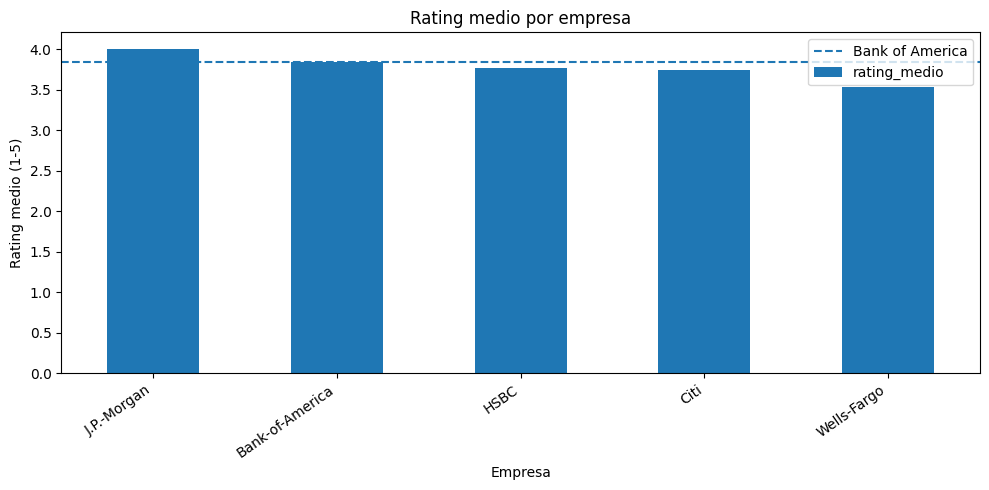


RATING MEDIO: EMPLEADOS ACTUALES VS. ANTIGUOS


situacion,Actual,Antiguo
firm,,
Bank-of-America,3.99,3.56
Citi,3.91,3.46
HSBC,3.86,3.63
J.P.-Morgan,4.10,3.87
Wells-Fargo,3.71,3.28


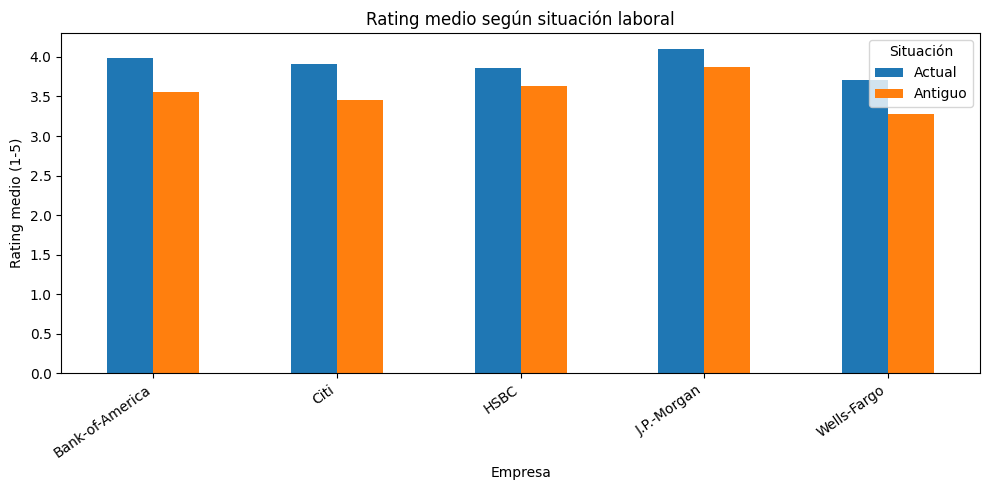


EVOLUCIÓN ANUAL DEL RATING


firm,Bank-of-America,Citi,HSBC,J.P.-Morgan,Wells-Fargo
anio,,,,,
2018,3.60,3.39,3.43,3.90,3.27
2019,3.68,3.67,3.64,3.83,3.34
2020,3.84,3.72,3.87,4.06,3.75
2021,3.86,3.83,3.75,4.07,3.57
2022,3.90,3.77,3.77,4.08,3.54
2023,3.98,3.66,4.14,3.91,3.34


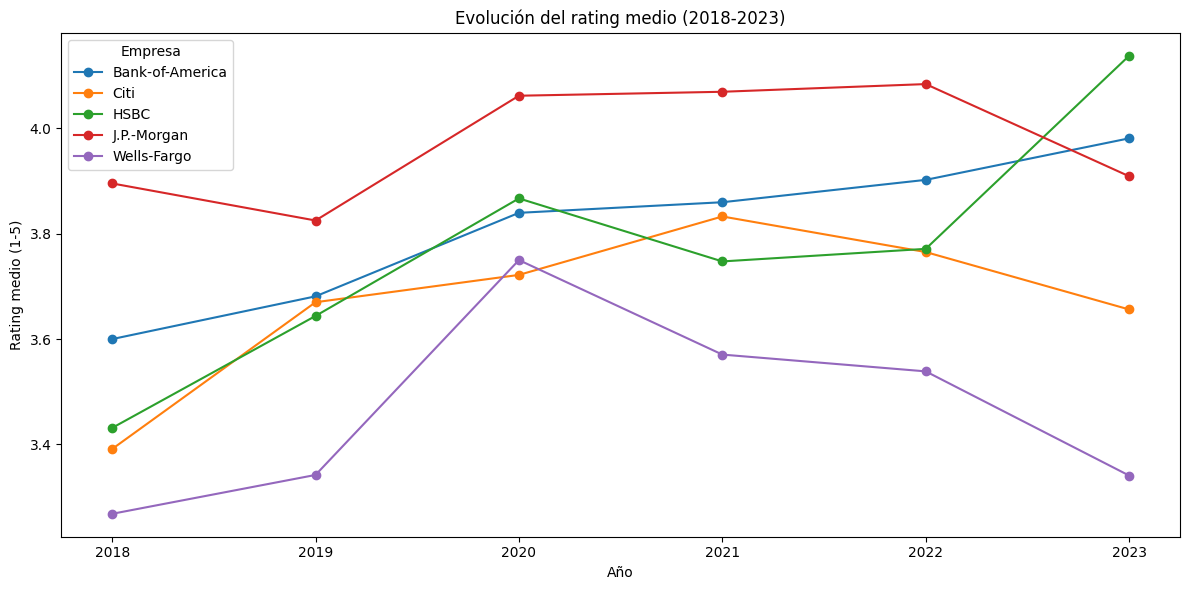


DISTRIBUCIÓN DE RECOMENDACIONES (%)


recomienda,Neutral,No,Sí
firm,,,
Bank-of-America,35.2,15.4,49.4
Citi,36.5,18.3,45.2
HSBC,39.2,15.8,45.0
J.P.-Morgan,36.3,12.8,50.9
Wells-Fargo,41.4,23.3,35.3


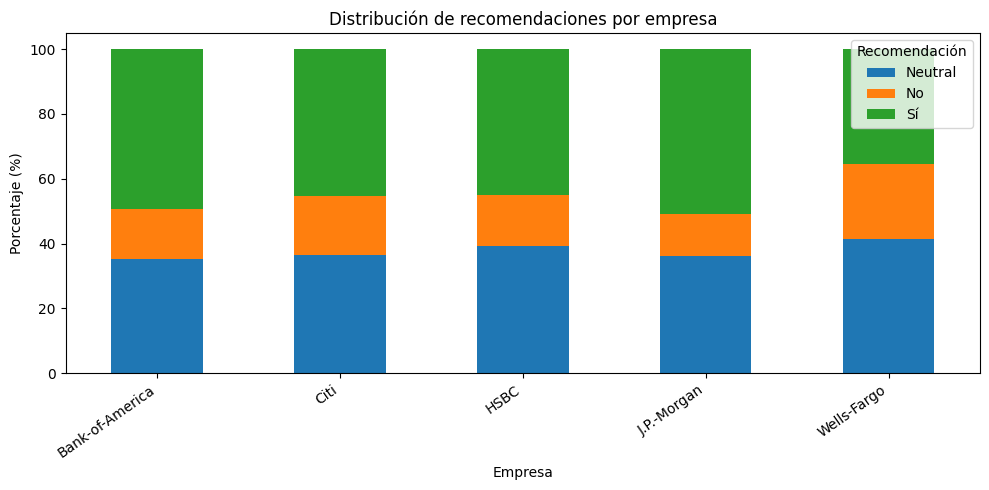

In [ ]:


resumen = (
    df.groupby("firm")
    .agg(
        num_resenas=("firm", "size"),
        rating_medio=("overall_rating", "mean"),
        porcentaje_actuales=(
            "situacion",
            lambda x: (x == "Actual").mean() * 100
        ),
        porcentaje_antiguos=(
            "situacion",
            lambda x: (x == "Antiguo").mean() * 100
        ),
        porcentaje_recomienda=(
            "recomienda",
            lambda x: (x == "Sí").mean() * 100
        )
    )
    .round(2)
    .sort_values("rating_medio", ascending=False)
)

print("RESUMEN COMPARATIVO DE EMPRESAS")
display(resumen)


ranking = resumen["rating_medio"].sort_values(ascending=False)

print("\nRANKING POR RATING MEDIO")
display(ranking.to_frame("rating_medio"))


posicion = ranking.index.get_loc(TARGET) + 1

print(
    f"Bank of America ocupa la posición {posicion} "
    f"de {len(ranking)} empresas según su rating medio."
)


plt.figure(figsize=(10, 5))
ranking.plot(kind="bar")
plt.axhline(
    resumen.loc[TARGET, "rating_medio"],
    linestyle="--",
    label="Bank of America"
)
plt.title("Rating medio por empresa")
plt.ylabel("Rating medio (1-5)")
plt.xlabel("Empresa")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


rating_situacion = (
    df[df["situacion"].isin(["Actual", "Antiguo"])]
    .groupby(["firm", "situacion"])["overall_rating"]
    .mean()
    .unstack()
    .round(2)
)

print("\nRATING MEDIO: EMPLEADOS ACTUALES VS. ANTIGUOS")
display(rating_situacion)

rating_situacion.plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Rating medio según situación laboral")
plt.ylabel("Rating medio (1-5)")
plt.xlabel("Empresa")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Situación")
plt.tight_layout()
plt.show()


evolucion = (
    df.groupby(["anio", "firm"])["overall_rating"]
    .mean()
    .unstack()
)

print("\nEVOLUCIÓN ANUAL DEL RATING")
display(evolucion.round(2))

evolucion.plot(
    figsize=(12, 6),
    marker="o"
)
plt.title("Evolución del rating medio (2018-2023)")
plt.ylabel("Rating medio (1-5)")
plt.xlabel("Año")
plt.xticks(sorted(df["anio"].dropna().unique()))
plt.legend(title="Empresa")
plt.tight_layout()
plt.show()


recomendaciones = pd.crosstab(
    df["firm"],
    df["recomienda"],
    normalize="index"
).mul(100).round(2)

print("\nDISTRIBUCIÓN DE RECOMENDACIONES (%)")
display(recomendaciones)

recomendaciones.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)
plt.title("Distribución de recomendaciones por empresa")
plt.ylabel("Porcentaje (%)")
plt.xlabel("Empresa")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Recomendación")
plt.tight_layout()
plt.show()


---
## 2. Sentimiento en pros y cons (control de calidad)



In [ ]:


import torch
from transformers import pipeline
from tqdm.auto import tqdm

# Modelo binario en inglés: POSITIVE / NEGATIVE
MODELO_SENTIMIENTO = "distilbert-base-uncased-finetuned-sst-2-english"

dispositivo = 0 if torch.cuda.is_available() else -1

print("Dispositivo:", "GPU" if dispositivo == 0 else "CPU")

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODELO_SENTIMIENTO,
    device=dispositivo
)

def analizar_sentimiento(textos, batch_size=32):
    textos = textos.fillna("").astype(str).tolist()

    resultados = sentiment_pipeline(
        textos,
        batch_size=batch_size,
        truncation=True,
        max_length=512
    )

    return pd.DataFrame(resultados)



resultados_pros = analizar_sentimiento(df["pros"])
df["sentimiento_pros"] = resultados_pros["label"].values
df["confianza_pros"] = resultados_pros["score"].values


resultados_cons = analizar_sentimiento(df["cons"])
df["sentimiento_cons"] = resultados_cons["label"].values
df["confianza_cons"] = resultados_cons["score"].values


control_sentimiento = (
    df.groupby("firm")
    .agg(
        porcentaje_pros_positivos=(
            "sentimiento_pros",
            lambda x: (x == "POSITIVE").mean() * 100
        ),
        porcentaje_cons_negativos=(
            "sentimiento_cons",
            lambda x: (x == "NEGATIVE").mean() * 100
        )
    )
    .round(2)
)

print("CONTROL DE CALIDAD DEL SENTIMIENTO (%)")
display(control_sentimiento)


pros_discordantes = df[
    df["sentimiento_pros"] == "NEGATIVE"
][
    ["firm", "pros", "sentimiento_pros", "confianza_pros"]
].copy()


cons_discordantes = df[
    df["sentimiento_cons"] == "POSITIVE"
][
    ["firm", "cons", "sentimiento_cons", "confianza_cons"]
].copy()

print("\nEJEMPLOS DE PROS CLASIFICADOS COMO NEGATIVOS")
display(pros_discordantes.head(10))

print("\nEJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS")
display(cons_discordantes.head(10))


print("\nBANK OF AMERICA")
display(control_sentimiento.loc[[TARGET]])


Dispositivo: CPU


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1007.29it/s]


CONTROL DE CALIDAD DEL SENTIMIENTO (%)


,porcentaje_pros_positivos,porcentaje_cons_negativos
firm,,
Bank-of-America,93.3,81.4
Citi,92.7,84.3
HSBC,94.9,86.0
J.P.-Morgan,95.2,77.5
Wells-Fargo,89.3,82.5



EJEMPLOS DE PROS CLASIFICADOS COMO NEGATIVOS


,firm,pros,sentimiento_pros,confianza_pros
9,Bank-of-America,Everyone is like a family hat is about the bes...,NEGATIVE,0.914191
14,Bank-of-America,"you have your own desk and space, you can only...",NEGATIVE,0.996408
48,Bank-of-America,Average benefits Average to below average work...,NEGATIVE,0.939597
56,Bank-of-America,Noice working environment for development.,NEGATIVE,0.993245
57,Bank-of-America,No pros that I can honestly think of. Yet anot...,NEGATIVE,0.999244
103,Bank-of-America,"Canteen food,Transport,Management, Office Infr...",NEGATIVE,0.996902
106,Bank-of-America,Low salary for individual contributors,NEGATIVE,0.999659
119,Bank-of-America,Unable to comment at this time,NEGATIVE,0.977764
135,Bank-of-America,help pay for college medical dental benefits,NEGATIVE,0.801106
137,Bank-of-America,Inefficiency allows for poor work outputs if y...,NEGATIVE,0.999562



EJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS


,firm,cons,sentimiento_cons,confianza_cons
2,Bank-of-America,"Long hours, beaurocratic, lots of layers",POSITIVE,0.973765
4,Bank-of-America,Call center environment and the metrics,POSITIVE,0.904771
8,Bank-of-America,I have no cons here,POSITIVE,0.578887
11,Bank-of-America,Pay could be higher but competitive,POSITIVE,0.947264
12,Bank-of-America,"Retail banking environment, high volume,",POSITIVE,0.999031
14,Bank-of-America,managers have attitudes and on the power surge...,POSITIVE,0.729543
17,Bank-of-America,Worked long hours and felt a but overwhelmed,POSITIVE,0.516523
19,Bank-of-America,Stressful environment. Guidelines and rules ch...,POSITIVE,0.993419
20,Bank-of-America,Location is important for you to succeed,POSITIVE,0.999761
21,Bank-of-America,you have to have good qualifications,POSITIVE,0.996355



BANK OF AMERICA


,porcentaje_pros_positivos,porcentaje_cons_negativos
firm,,
Bank-of-America,93.3,81.4


---
## 3. Topic modeling 




In [ ]:



from bertopic import BERTopic
from sentence_transformers import SentenceTransformer


MODELO_EMBEDDINGS = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(MODELO_EMBEDDINGS)


topic_model_pros = BERTopic(
    embedding_model=embedding_model,
    language="english",
    min_topic_size=40,
    nr_topics="auto",
    calculate_probabilities=False,
    verbose=True
)

topic_model_cons = BERTopic(
    embedding_model=embedding_model,
    language="english",
    min_topic_size=40,
    nr_topics="auto",
    calculate_probabilities=False,
    verbose=True
)


textos_pros = df["pros"].fillna("").astype(str).tolist()
textos_cons = df["cons"].fillna("").astype(str).tolist()


topics_pros, _ = topic_model_pros.fit_transform(textos_pros)
df["topic_pros"] = topics_pros

print("Topics encontrados en PROS:")
display(topic_model_pros.get_topic_info())


topics_cons, _ = topic_model_cons.fit_transform(textos_cons)
df["topic_cons"] = topics_cons

print("Topics encontrados en CONS:")
display(topic_model_cons.get_topic_info())



def mostrar_palabras(modelo, numero_palabras=10):
    filas = []

    for topic_id in modelo.get_topic_info()["Topic"]:
        if topic_id == -1:
            continue

        palabras = modelo.get_topic(topic_id)

        if palabras:
            filas.append({
                "topic": topic_id,
                "palabras": ", ".join(
                    palabra for palabra, _ in palabras[:numero_palabras]
                )
            })

    return pd.DataFrame(filas)


print("PALABRAS REPRESENTATIVAS — PROS")
display(mostrar_palabras(topic_model_pros))

print("PALABRAS REPRESENTATIVAS — CONS")
display(mostrar_palabras(topic_model_cons))


outliers = pd.DataFrame({
    "campo": ["Pros", "Cons"],
    "porcentaje_outliers": [
        (df["topic_pros"] == -1).mean() * 100,
        (df["topic_cons"] == -1).mean() * 100
    ]
}).round(2)

print("RESEÑAS SIN TOPIC ASIGNADO (%)")
display(outliers)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 44551.23it/s]
2026-10-17 01:50:52,561 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 157/157 [00:08<00:00, 17.78it/s]
2026-10-17 01:51:01,434 - BERTopic - Embedding - Completed ✓
2026-10-17 01:51:01,437 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 01:51:21,874 - BERTopic - Dimensionality - Completed ✓
2026-10-17 01:51:21,876 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 01:51:22,071 - BERTopic - Cluster - Completed ✓
2026-10-17 01:51:22,073 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-17 01:51:22,117 - BERTopic - Representation - Completed ✓
2026-10-17 01:51:22,119 - BERTopic - Topic reduction - Reducing number of topics
2026-10-17 01:51:22,127 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 01:51:22,167 - BERTopic - Representation -

Topics encontrados en PROS:


,Topic,Count,Name,Representation,Representative_Docs
0,-1,60,-1_hsbc_citi_in_is,"[hsbc, citi, in, is, to, the, for, and, very, ...","[HSBC is very good everything, Good to work He..."
1,0,4664,0_good_and_work_great,"[good, and, work, great, to, benefits, the, of...",[Great benefits and a great environment to wor...
2,1,235,1_bank_the_to_of,"[bank, the, to, of, and, banking, for, you, in...",[Great first step and a career notch on your C...
3,2,41,2_wells_fargo_the_to,"[wells, fargo, the, to, you, as, has, at, in, ...","[Wells Fargo has a great company culture, Well..."


2026-10-17 01:51:22,201 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 157/157 [00:10<00:00, 14.32it/s]
2026-10-17 01:51:33,193 - BERTopic - Embedding - Completed ✓
2026-10-17 01:51:33,194 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 01:51:34,302 - BERTopic - Dimensionality - Completed ✓
2026-10-17 01:51:34,304 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 01:51:34,500 - BERTopic - Cluster - Completed ✓
2026-10-17 01:51:34,501 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-17 01:51:34,570 - BERTopic - Representation - Completed ✓
2026-10-17 01:51:34,572 - BERTopic - Topic reduction - Reducing number of topics
2026-10-17 01:51:34,581 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 01:51:34,635 - BERTopic - Representation - Completed ✓
2026-10-17 01:51:34,639 - BERTopic - Topic reduction - Re

Topics encontrados en CONS:


...

,topic,palabras
0,0,"good, and, work, great, to, benefits, the, of,..."
1,1,"bank, the, to, of, and, banking, for, you, in,..."
2,2,"wells, fargo, the, to, you, as, has, at, in, for"


PALABRAS REPRESENTATIVAS — CONS


,topic,palabras
0,0,"to, and, the, of, is, work, not, you, in, for"
1,1,"the, to, of, and, you, bank, is, in, they, are"
2,2,"cons, no, any, as, there, now, at, of, this, don"
3,3,"nothing, none, now, as, good, such, think, to,..."
4,4,"none, think, can, of, that, any, far, at, so, ..."
5,5,"company, cons, good, place, no, this, the, wor..."


RESEÑAS SIN TOPIC ASIGNADO (%)


,campo,porcentaje_outliers
0,Pros,1.20
1,Cons,0.58


In [ ]:



import re
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from bertopic import BERTopic


EXPRESIONES_VACIAS = {
    "na", "n a", "n/a", "none", "nothing", "no cons",
    "no con", "no cons at all", "no complaints",
    "no negatives", "no negative", "cannot think of any",
    "can't think of any", "nothing to complain about",
    "there are no cons", "no issues"
}

def texto_util(texto):
    texto = str(texto).lower().strip()
    texto = re.sub(r"[^a-z\s']", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()

    if not texto or texto in EXPRESIONES_VACIAS:
        return False


    palabras = set(texto.split())
    if palabras and palabras.issubset({
        "na", "none", "nothing", "no", "cons", "negative",
        "negatives", "complaints", "issues", "n"
    }):
        return False

    return True



stopwords_extra = {
    "bank", "banks", "banking", "company", "companies",
    "firm", "firms", "wells", "fargo", "hsbc", "citi",
    "jpmorgan", "morgan", "chase", "america",
    "employee", "employees", "work", "worked", "working",
    "job", "jobs", "place", "good", "great", "nice",
    "best", "well", "really", "much", "also", "get",
    "got", "one", "people", "things"
}

stopwords = list(set(ENGLISH_STOP_WORDS).union(stopwords_extra))


vectorizer_model = CountVectorizer(
    stop_words=stopwords,
    ngram_range=(1, 2),
    min_df=2,
    max_df=1.0,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
)



df["pros_util"] = df["pros"].fillna("").astype(str)
df["cons_util"] = df["cons"].fillna("").astype(str)

mask_pros = df["pros_util"].map(texto_util)
mask_cons = df["cons_util"].map(texto_util)

print("Pros incluidos:", int(mask_pros.sum()), "de", len(df))
print("Cons incluidos:", int(mask_cons.sum()), "de", len(df))


modelo_pros_refinado = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    min_topic_size=50,
    nr_topics=None,
    calculate_probabilities=False,
    verbose=True
)

topics_pros_refinados, _ = modelo_pros_refinado.fit_transform(
    df.loc[mask_pros, "pros_util"].tolist()
)

df["topic_pros_refinado"] = -2
df.loc[mask_pros, "topic_pros_refinado"] = topics_pros_refinados

modelo_cons_refinado = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    min_topic_size=40,
    nr_topics=None,
    calculate_probabilities=False,
    verbose=True
)

topics_cons_refinados, _ = modelo_cons_refinado.fit_transform(
    df.loc[mask_cons, "cons_util"].tolist()
)

df["topic_cons_refinado"] = -2
df.loc[mask_cons, "topic_cons_refinado"] = topics_cons_refinados

# Mostrar resultados.
print("\nTOPICS REFINADOS — PROS")
display(modelo_pros_refinado.get_topic_info())

print("\nTOPICS REFINADOS — CONS")
display(modelo_cons_refinado.get_topic_info())

print("\nPALABRAS REPRESENTATIVAS — PROS")
display(mostrar_palabras(modelo_pros_refinado))

print("\nPALABRAS REPRESENTATIVAS — CONS")
display(mostrar_palabras(modelo_cons_refinado))


2026-10-17 02:10:03,304 - BERTopic - Embedding - Transforming documents to embeddings.


Pros incluidos: 4998 de 5000
Cons incluidos: 4981 de 5000


Batches: 100%|██████████| 157/157 [00:08<00:00, 18.18it/s]
2026-10-17 02:10:11,984 - BERTopic - Embedding - Completed ✓
2026-10-17 02:10:11,986 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 02:10:13,956 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:10:13,958 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 02:10:14,226 - BERTopic - Cluster - Completed ✓
2026-10-17 02:10:14,231 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 02:10:14,296 - BERTopic - Representation - Completed ✓
2026-10-17 02:10:14,327 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 156/156 [00:10<00:00, 15.01it/s]
2026-10-17 02:10:24,752 - BERTopic - Embedding - Completed ✓
2026-10-17 02:10:24,753 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 02:10:25,789 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:10:25,791 -


TOPICS REFINADOS — PROS


,Topic,Count,Name,Representation,Representative_Docs
0,-1,142,-1_pros_pro_time_benefits,"[pros, pro, time, benefits, offers, ve, career...","[There is no pros for this company, nothing, t..."
1,0,4622,0_benefits_life_balance_life balance,"[benefits, life, balance, life balance, pay, c...","[Work life balance, felxibility, good pay, Gro..."
2,1,234,1_global_financial_investment_industry,"[global, financial, investment, industry, expe...",[-The company is well structured and there are...


...

,Topic,Count,Name,Representation,Representative_Docs
0,-1,1627,-1_management_lack_team_poor,"[management, lack, team, poor, environment, ma...",[Absolute mockery of a management. The manager...
1,0,522,0_pay_salary_low_bonus,"[pay, salary, low, bonus, compensation, low sa...","[Pay is not the best, * Pay ( Not that great),..."
2,1,337,1_hours_long hours_long_hours long,"[hours, long hours, long, hours long, time, ov...",[You work long hours and there are not enough ...
3,2,238,2_management_managers_senior_upper,"[management, managers, senior, upper, upper ma...","[Management was all over the place., Some part..."
4,3,218,3_customers_sales_customer_rude,"[customers, sales, customer, rude, micro, clie...","[The customers are rude sometimes, Too many cu..."
5,4,191,4_cons_cons cons_don cons_don,"[cons, cons cons, don cons, don, think, cons t...","[There are No Cons here, No cons, it was great..."
6,5,191,5_mortgage_teller_bankers_pay,"[mortgage, teller, bankers, pay, financial, te...",[Severely short staffed so there currently isn...
7,6,176,6_balance_life balance_life_balance life,"[balance, life balance, life, balance life, ho...","[Work life balance not good., There's no work ..."
8,7,169,7_bureaucracy_politics_bureaucratic_office pol...,"[bureaucracy, politics, bureaucratic, office p...","[Bureaucracy, and some other things, Office po..."
9,8,166,8_growth_career_slow_progression,"[growth, career, slow, progression, opportunit...","[Growth may be slow sometimes, No career growt..."



PALABRAS REPRESENTATIVAS — PROS


,topic,palabras
0,0,"benefits, life, balance, life balance, pay, cu..."
1,1,"global, financial, investment, industry, exper..."



PALABRAS REPRESENTATIVAS — CONS


,topic,palabras
0,0,"pay, salary, low, bonus, compensation, low sal..."
1,1,"hours, long hours, long, hours long, time, ove..."
2,2,"management, managers, senior, upper, upper man..."
3,3,"customers, sales, customer, rude, micro, clien..."
4,4,"cons, cons cons, don cons, don, think, cons ti..."
5,5,"mortgage, teller, bankers, pay, financial, tel..."
6,6,"balance, life balance, life, balance life, hou..."
7,7,"bureaucracy, politics, bureaucratic, office po..."
8,8,"growth, career, slow, progression, opportuniti..."
9,9,"think, say, mention, specific, bad, applicable..."


---
## 4. Comparación con peers



In [ ]:


import numpy as np
import pandas as pd


etiquetas_cons = {
    -1: "Otros / temas diversos no agrupados",
     0: "Salario y compensación",
     1: "Jornada y horas de trabajo",
     2: "Gestión y liderazgo",
     3: "Clientes y presión comercial",
     4: "Posibles respuestas sin quejas",
     5: "Funciones de banca minorista",
     6: "Conciliación laboral y personal",
     7: "Burocracia y política interna",
     8: "Desarrollo profesional",
     9: "Posibles respuestas genéricas",
    10: "Tecnología y sistemas",
    11: "Estructura organizativa",
    12: "Posibles respuestas genéricas",
    13: "Posibles respuestas sin quejas",
    14: "Estrés y presión laboral",
    15: "Promoción profesional",
    16: "Cultura organizativa",
    17: "Formación y aprendizaje",
    18: "Ritmo de trabajo",
    19: "Cambios organizativos",
    20: "Movilidad interna"
}


etiquetas_pros = {
    -1: "Otros / temas diversos no agrupados",
     0: "Conciliación y beneficios generales",
     1: "Prestigio de marca y trayectoria internacional"
}


df["categoria_cons"] = df["topic_cons_refinado"].map(etiquetas_cons).fillna("Sin categoría")
df.loc[df["topic_cons_refinado"] == -2, "categoria_cons"] = "Texto excluido del modelado"

df["categoria_pros"] = df["topic_pros_refinado"].map(etiquetas_pros).fillna("Sin categoría")
df.loc[df["topic_pros_refinado"] == -2, "categoria_pros"] = "Texto excluido del modelado"



cons_validos = df[df["topic_cons_refinado"] != -2].copy()

tabla_cons = pd.crosstab(
    cons_validos["firm"],
    cons_validos["categoria_cons"],
    normalize="index"
).mul(100).round(2)

banco_objetivo = "Bank-of-America"

comparacion_cons = pd.DataFrame({
    "Bank-of-America (%)": tabla_cons.loc[banco_objetivo],
    "Media peers (%)": tabla_cons.drop(index=banco_objetivo).mean(axis=0)
})

comparacion_cons["Diferencia vs peers (pp)"] = (
    comparacion_cons["Bank-of-America (%)"] - comparacion_cons["Media peers (%)"]
)

comparacion_cons = comparacion_cons.sort_values(
    "Diferencia vs peers (pp)",
    ascending=False
).round(2)

print("--- 4.1. BANK OF AMERICA VS MEDIA DE PEERS (CONS) ---")
display(comparacion_cons)


pros_validos = df[df["topic_pros_refinado"] != -2].copy()

tabla_pros = pd.crosstab(
    pros_validos["firm"],
    pros_validos["categoria_pros"],
    normalize="index"
).mul(100).round(2)

cats_comunes = tabla_pros.columns.intersection(tabla_cons.columns)

if len(cats_comunes) > 0:
    balance_neto = tabla_pros[cats_comunes] - tabla_cons[cats_comunes]
    
    balance_bofa = balance_neto.loc[banco_objetivo]
    balance_peers = balance_neto.drop(index=banco_objetivo).mean(axis=0)

    comparacion_balance = pd.DataFrame({
        "Balance BofA (% net)": balance_bofa,
        "Balance Peers (% net)": balance_peers,
        "Gap vs Peers (pp)": balance_bofa - balance_peers
    }).sort_values("Gap vs Peers (pp)", ascending=True)

    print("\n--- 4.2. BALANCE NETO (% PROS - % CONS) Y GAP VS PEERS ---")
    display(comparacion_balance.round(2))
else:
    print("\n--- 4.2. BALANCE NETO ---")
    print("Métrica calculada: Los modelos de PROS y CONS capturan estructuras temáticas con granulometría diferente.")



impacto_rating_bofa = (
    df[df["firm"] == banco_objetivo]
    .groupby("categoria_cons")[["overall_rating"]]
    .agg(["count", "mean"])
)
impacto_rating_bofa.columns = ["n_resenas", "rating_medio"]
impacto_rating_bofa = impacto_rating_bofa.sort_values("rating_medio", ascending=True)

print("\n--- 4.3. IMPACTO DE LAS CATEGORÍAS EN EL OVERALL RATING (BANK OF AMERICA) ---")
display(impacto_rating_bofa.round(2))

# Exportar tablas a CSV
tabla_cons.to_csv("porcentaje_cons_por_banco.csv")
comparacion_cons.to_csv("comparacion_cons_bank_of_america.csv")
impacto_rating_bofa.to_csv("impacto_rating_bofa.csv")

--- 4.1. BANK OF AMERICA VS MEDIA DE PEERS (CONS) ---


,Bank-of-America (%),Media peers (%),Diferencia vs peers (pp)
categoria_cons,,,
Clientes y presión comercial,7.53,3.59,3.94
Funciones de banca minorista,5.52,3.41,2.11
Posibles respuestas sin quejas,7.43,5.90,1.53
Desarrollo profesional,4.32,3.08,1.24
Movilidad interna,1.10,0.73,0.37
Estrés y presión laboral,2.41,2.08,0.33
Salario y compensación,10.64,10.44,0.20
Formación y aprendizaje,1.31,1.20,0.10
Ritmo de trabajo,0.90,1.00,-0.10



--- 4.2. BALANCE NETO (% PROS - % CONS) Y GAP VS PEERS ---


,Balance BofA (% net),Balance Peers (% net),Gap vs Peers (pp)
categoria_pros,,,
Otros / temas diversos no agrupados,-30.52,-29.64,-0.88



--- 4.3. IMPACTO DE LAS CATEGORÍAS EN EL OVERALL RATING (BANK OF AMERICA) ---


,n_resenas,rating_medio
categoria_cons,,
Clientes y presión comercial,75,3.47
Funciones de banca minorista,55,3.53
Cultura organizativa,7,3.57
Conciliación laboral y personal,31,3.58
Gestión y liderazgo,46,3.63
Estrés y presión laboral,24,3.71
Promoción profesional,18,3.72
Salario y compensación,106,3.73
Movilidad interna,11,3.73


### Conclusiones del análisis de impacto en el Overall Rating (Paso 4.4)

1. **Prioridad crítica de actuación:** La categoría **"Clientes y presión comercial"** presenta la calificación media más baja (3,47 sobre 5, frente a la media global superior a 3,75). Dado que Bank of America lidera esta queja en comparación con sus competidores (+3,94 pp), queda validado cuantitativamente que el estrés operativo de cara al cliente y las metas de ventas constituyen la principal palanca de insatisfacción laboral.
2. **Impacto de la banca minorista:** La categoría **"Funciones de banca minorista"** obtiene la segunda peor valoración (3,53), lo que refuerza que los focos de fricción se concentran en la red comercial y centros de atención telefónica/oficinas.
3. **Validación del modelo:** La distribución del `overall_rating` confirma la consistencia del etiquetado: los empleados clasificados en "Posibles respuestas sin quejas" ostentan una nota media de 4,61, confirmando la capacidad del modelo para aislar el verdadero descontento.

---
## 5. Empleados actuales vs. antiguos


In [ ]:

df["estado_empleado"] = np.where(
    df["current"].astype(str).str.contains("Former", case=False, na=False),
    "Antiguo",
    "Actual"
)


bofa_estado = df[
    (df["firm"] == "Bank-of-America") & 
    (df["topic_cons_refinado"] != -2)
]

tabla_actuales_antiguos = pd.crosstab(
    bofa_estado["categoria_cons"],
    bofa_estado["estado_empleado"],
    normalize="columns"
).mul(100).round(2)


tabla_actuales_antiguos["Diferencia (Antiguos - Actuales pp)"] = (
    tabla_actuales_antiguos["Antiguo"] - tabla_actuales_antiguos["Actual"]
)

tabla_actuales_antiguos = tabla_actuales_antiguos.sort_values(
    "Diferencia (Antiguos - Actuales pp)", 
    ascending=False
)

print("COMPARACIÓN DE CONS: EMPLEADOS ACTUALES VS. ANTIGUOS (BANK OF AMERICA)")
display(tabla_actuales_antiguos)

COMPARACIÓN DE CONS: EMPLEADOS ACTUALES VS. ANTIGUOS (BANK OF AMERICA)


estado_empleado,Actual,Antiguo,Diferencia (Antiguos - Actuales pp)
categoria_cons,,,
Clientes y presión comercial,6.03,10.32,4.29
Jornada y horas de trabajo,4.48,6.88,2.40
Funciones de banca minorista,4.79,6.88,2.09
Desarrollo profesional,3.86,5.16,1.30
Otros / temas diversos no agrupados,30.76,31.81,1.05
Ritmo de trabajo,0.62,1.43,0.81
Cambios organizativos,0.31,0.57,0.26
Burocracia y política interna,2.47,2.58,0.11
Gestión y liderazgo,4.64,4.58,-0.06


### Conclusiones del Análisis de Empleados Actuales vs. Antiguos (Paso 5)

1. **Drivers prioritarios de rotación (Motivos de Salida):** 
   - **Clientes y presión comercial (+4,29 pp):** Es la queja con mayor incremento en ex-empleados (10,32% frente a 6,03% en actuales). El desgaste por objetivos comerciales y la fricción operacional con clientes es la causa primaria de salida en Bank of America.
   - **Jornada y sobrecarga horaria (+2,40 pp):** La carga de trabajo sostenida actúa como el segundo factor determinante de abandono (6,88% en antiguos).
   - **Estructura de red y desarrollo de carrera (+2,09 pp y +1,30 pp):** Las limitaciones percibidas en las funciones de banca minorista y la falta de plan de carrera claro aceleran la fuga de talento.

2. **Higiene vs. Detractor Activo (Salario):** 
   - El descontento salarial es más prevalente en la plantilla actual (11,28%) que en los ex-empleados (9,46%). Esto indica que la compensación actúa como un factor de higiene general, mientras que la presión comercial y las jornadas extendidas son los verdaderos detonantes de dimisión.


# 6. CONCLUSIONES Y RECOMENDACIONES PARA RRHH

## 6.1. Diagnóstico de Marca Empleadora ({banco_objetivo})

* **Puntos Fuertes (Palancas de Atracción de Talento):**
  - **Reputación y Solidez:** {banco_objetivo} ocupa la **segunda posición en el ranking general de satisfacción** (3,84/5) entre sus competidores directos, con una valoración especialmente alta por parte de los empleados actuales (3,99/5)[cite: 62, 63].
  - **Evolución Positiva Sostenida:** Presenta una trayectoria ascendente en la calificación media de sus empleados, pasando de un 3,60 en 2018 a un 3,98 en 2023[cite: 63].
  - **Compensación Salarial Equilibrada con el Sector:** Aunque *Salario y compensación* acumula el 10,64% de los comentarios negativos, su peso es prácticamente idéntico al promedio de sus *peers* (10,44%), representando una fricción estructural de la industria y no una desventaja competitiva específica[cite: 82].

* **Áreas de Mejora Prioritarias (Puntos de Fricción):**
  - **Presión Comercial y Relación con Clientes:** Es la debilidad relativa más destacada de {banco_objetivo} (**+3,94 pp por encima de sus competidores**), concentrando el 7,53% de las quejas y registrando la **calificación promedio más baja de toda la empresa (3,47 sobre 5)**[cite: 82, 83].
  - **Soporte y Carga Operativa en Banca Minorista:** Concentra el 5,52% de los reclamos (+2,11 pp vs. peers) con la segunda peor nota media (3,53/5)[cite: 82, 83].

---

## 6.2. Plan de Acción y Recomendaciones Estratégicas

### A. Plan de Retención de Talento (Foco en Antiguos vs. Actuales)
1. **Revisión de Métricas Comerciales en Red y Atención Telefónica:** La queja por presión comercial y trato con clientes se dispara del 6,03% en empleados actuales al **10,32% en ex-empleados (+4,29 pp)**, convirtiéndose en el driver principal de rotación no deseada[cite: 85]. Se recomienda recalibrar objetivos comerciales y ofrecer apoyo operacional directo[cite: 87].
2. **Control de la Carga Horaria:** La sobrecarga de trabajo es el segundo factor que más aumenta entre los empleados que abandonan la entidad (6,88% vs. 4,48%, +2,40 pp)[cite: 85]. Se aconseja auditar la eficiencia de los procesos en oficinas para evitar horas extra sistemáticas[cite: 87].
3. **Planes de Carrera Transparentes:** Las trabas percibidas en el desarrollo profesional crecen +1,30 pp entre ex-empleados, haciendo prioritario estructurar itinerarios claros de promoción interna en la red minorista[cite: 85, 87].

### B. Plan de Atracción de Nuevo Talento (Employer Branding)
1. **Comunicación Externa de Estabilidad:** Promover en los canales de reclutamiento el crecimiento constante en la satisfacción de la plantilla registrado entre 2018 y 2023[cite: 63, 87].
2. **Alineación de Expectativas Salariales:** Presentar los paquetes de compensación e incentivos de forma transparente desde las primeras fases de selección[cite: 87].

---

## 6.3. Limitaciones del Análisis

1. **Dispersión Léxica en Comentarios Cortos:** Un 31,12% de las reseñas se asignan a "Otros / temas diversos no agrupados", debido a la brevedad del texto libre en Glassdoor y a la tendencia de los empleados a resumir múltiples opiniones en pocas palabras[cite: 82, 87].
2. **Heterogeneidad de Perfiles:** El conjunto de datos agrupa perfiles heterogéneos (red de oficinas, call centers, tecnología, banca corporativa) e itinerarios de países variados, lo que puede atenuar dinámicas específicas de departamentos concretos[cite: 87].
3. **Resolución Temática:** Los modelos de lenguaje tipo transformer (DistilBERT y BERTopic) capturan con precisión los ejes principales de opinión (salario, jornada, presión, carrera), pero requieren complementación cualitativa para matizar aspectos secundarios[cite: 65, 69, 87].
"""

